In [17]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / ".env").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"
RESULTS_DIR = project_root / "results"

In [3]:
df = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv",
    index_col="date",
    parse_dates=True
)

In [9]:
total_duration = pd.Timedelta(df.index[-1] - df.index[0])
total_days = total_duration.days
year_count = total_days / 365.25
year_count

12.876112251882272

In [12]:
btc_cagr = ((df["price_btc"].iloc[-1] / df["price_btc"].iloc[0]) ** (1 / year_count) - 1) * 100.0
btc_cagr

np.float64(43.012032962692935)

In [13]:
spy_cagr = ((df["price_spy"].iloc[-1] / df["price_spy"].iloc[0]) ** (1 / year_count) - 1) * 100.0
spy_cagr

np.float64(13.504402440602048)

In [19]:
summary = pd.DataFrame(
    {
        "CAGR": [btc_cagr, spy_cagr],
    },
    index=["BTC", "SPY"],
)

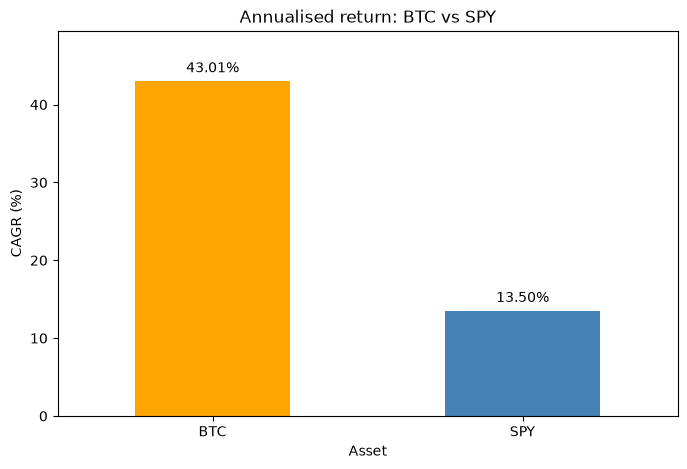

In [20]:
ax = summary["CAGR"].plot.bar(
    figsize=(8, 5),
    color=["orange", "steelblue"],
    rot=0,
)
ax.set_title("Annualised return: BTC vs SPY")
ax.set_xlabel("Asset")
ax.set_ylabel("CAGR (%)")
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.margins(y=0.15)

In [21]:
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "annualised_returns.png", dpi=300)
plt.show()